# BÁO CÁO THỰC HÀNH LAB 3: HUGGING FACE & FINE-TUNING DISTILBERT
## Chuyên đề: Sentiment Analysis trên Bộ Dữ Liệu IMDb Movie Reviews
**Môn học:** Deep Learning (Học sâu)  
**Phương pháp:** Pretrained Transformer & Transfer Learning (Fine-tuning)  
**Mô hình sử dụng:** DistilBERT (`distilbert-base-uncased`, `distilbert-base-uncased-finetuned-sst-2-english`)  
**Thư viện chính:** PyTorch, Hugging Face `transformers`, `datasets`, `evaluate`, Scikit-learn, Scipy, Pandas, Matplotlib

---

### MỤC LỤC BÁO CÁO
1. [PHẦN 1. Giới Thiệu & Cơ Sở Lý Thuyết (Introduction & Theoretical Background)](#sec1)
   - [1.1 Tổng quan bài toán Sentiment Analysis](#sec1_1)
   - [1.2 Hệ sinh thái Hugging Face & Kiến trúc DistilBERT](#sec1_2)
   - [1.3 Sơ đồ quy trình thực nghiệm tổng thể](#sec1_3)
2. [PHẦN 2. Exercise 1 — Sentiment Analysis với Pretrained Model](#sec2)
   - [2.1 Khởi tạo môi trường & Kiểm tra phần cứng](#sec2_1)
   - [2.2 Phân loại cảm xúc nhanh bằng Pipeline & Đánh giá Calibration](#sec2_2)
   - [2.3 Mổ xẻ cơ chế hoạt động của Tokenizer (WordPiece, Special Tokens, Masks)](#sec2_3)
   - [2.4 Suy luận trực tiếp bằng PyTorch & Kiểm chứng toán học Logits $\to$ Softmax](#sec2_4)
   - [2.5 Đánh giá & Kết luận kỹ thuật Exercise 1](#sec2_5)
3. [PHẦN 3. Exercise 2 — Fine-tuning DistilBERT trên Bộ Dữ Liệu IMDb](#sec3)
   - [3.1 Tải dữ liệu IMDb & Kiểm tra cấu trúc](#sec3_1)
   - [3.2 Khám phá dữ liệu chuyên sâu (EDA) & Thống kê độ dài Token](#sec3_2)
   - [3.3 Phân chia dữ liệu & Chiến lược chống rò rỉ (No Data Leakage)](#sec3_3)
   - [3.4 Tiền xử lý Tokenization & Kỹ thuật Dynamic Padding](#sec3_4)
   - [3.5 Khởi tạo mô hình DistilBERT & Cấu hình Hàm đánh giá đa chỉ số](#sec3_5)
   - [3.6 Thiết kế thí nghiệm & Thiết lập các mốc Baseline so sánh chuẩn](#sec3_6)
   - [3.7 Cấu hình Siêu tham số (`TrainingArguments`) & Thực thi Huấn luyện (`Trainer`)](#sec3_7)
   - [3.8 Phân tích đường cong học tập (Learning Curves) & Đánh giá quá trình hội tụ](#sec3_8)
   - [3.9 Đánh giá toàn diện trên Test Set & Phân tích khoảng tin cậy Wilson 95%](#sec3_9)
   - [3.10 Trực quan hóa kết quả đánh giá (Confusion Matrix & Per-class Metrics)](#sec3_10)
   - [3.11 Phân tích sai số (Error Analysis), Kiểm định Fisher & Mổ xẻ các ca lỗi điển hình](#sec3_11)
   - [3.12 Kiểm chứng lưu và nạp lại mô hình (`outputs/final_model/`)](#sec3_12)
   - [3.13 Tổng kết, Hạn chế & Hướng phát triển](#sec3_13)

---


<a id="sec1"></a>
# PHẦN 1. GIỚI THIỆU & CƠ SỞ LÝ THUYẾT (INTRODUCTION & THEORETICAL BACKGROUND)

<a id="sec1_1"></a>
### 1.1 Tổng quan bài toán Sentiment Analysis
**Phân tích cảm xúc (Sentiment Analysis)** là một trong những bài toán kinh điển và quan trọng nhất trong Xử lý Ngôn ngữ Tự nhiên (NLP). Mục tiêu là xác định thái độ, quan điểm hoặc cảm xúc chủ quan của tác giả ẩn sau một đoạn văn bản. Trong phạm vi bài thực hành này, chúng ta giải quyết bài toán **phân loại nhị phân (Binary Classification)** trên các bài đánh giá phim:
$$f: \mathcal{X} \to \mathcal{Y} = \{0, 1\}$$
Trong đó:
- $0$ tương ứng với nhãn **NEGATIVE** (Đánh giá tiêu cực).
- $1$ tương ứng với nhãn **POSITIVE** (Đánh giá tích cực).

<a id="sec1_2"></a>
### 1.2 Hệ sinh thái Hugging Face & Kiến trúc DistilBERT
Hệ sinh thái **Hugging Face** đã trở thành chuẩn mực công nghiệp trong NLP hiện đại nhờ cung cấp các công cụ module hóa:
- **`transformers`:** Cung cấp hàng nghìn kiến trúc Transformer tiên tiến cùng trọng số tiền huấn luyện (Pre-trained weights).
- **`datasets`:** Thư viện tải, tiền xử lý và truyền dữ liệu theo luồng hiệu năng cao.
- **`evaluate`:** Bộ công cụ tính toán các chỉ số đánh giá chuẩn hóa (Accuracy, F1, Precision, Recall).

**Kiến trúc DistilBERT:**
DistilBERT (Sanh et al., 2019) là một phiên bản rút gọn, gọn nhẹ của BERT (Bidirectional Encoder Representations from Transformers) được huấn luyện thông qua kỹ thuật **chưng cất tri thức (Knowledge Distillation)**:
- **Kích thước:** Giảm 40% số lượng tham số so với BERT-base (khoảng 66 triệu tham số so với 110 triệu).
- **Tốc độ:** Tăng tốc độ suy luận thêm 60%.
- **Hiệu năng:** Duy trì tới 97% năng lực hiểu ngôn ngữ của BERT trên điểm chuẩn GLUE.
- **Cấu trúc:** Gồm 6 lớp Transformer Encoder, 12 Attention Heads, ẩn chiều (hidden dimension) $d = 768$.

<a id="sec1_3"></a>
### 1.3 Sơ đồ quy trình thực nghiệm tổng thể
Quy trình thực nghiệm từ chuẩn bị dữ liệu, tinh chỉnh mô hình đến đánh giá và phân tích lỗi được mô hình hóa như sau:

**Quy trình thực nghiệm tổng thể (End-to-End Workflow Pipeline):**

$$\text{IMDb Dataset} \longrightarrow \text{Data Splitting} \longrightarrow \text{EDA} \longrightarrow \text{Tokenization} \longrightarrow \text{Trainer Fine-tuning} \longrightarrow \text{Evaluation & Error Analysis} \longrightarrow \text{Deployment}$$

| Giai đoạn | Thao tác kỹ thuật chính | Kết quả đầu ra |
| :--- | :--- | :--- |
| **1. Chuẩn bị dữ liệu** | Tải IMDb qua `datasets`, phân chia tập độc lập không rò rỉ | Train (800) / Val (200) / Test (200) |
| **2. Phân tích EDA** | Khảo sát cân bằng nhãn & phân bố độ dài chuỗi token | Nhãn cân bằng $50/50$, $87.5\%$ mẫu vượt 128 tokens |
| **3. Tiền xử lý** | WordPiece Sub-words & Dynamic Padding (`DataCollator`) | Tensor `input_ids`, `attention_mask` theo batch |
| **4. Thiết lập Baseline** | Đo Majority Rule (Test) và Untrained Random Head (Val) | Mốc đối chứng: Maj $52.00\%$, Untrained Val $44.00\%$ |
| **5. Huấn luyện (Fine-tuning)**| Tinh chỉnh mô hình 2 epochs với Hugging Face `Trainer` | Checkpoint tốt nhất tại Epoch 2 |
| **6. Đánh giá kiểm thử** | Đo Test Set độc lập & Khoảng tin cậy Wilson 95% | Test Acc $74.50\%$, CI $[68.04\%, 80.04\%]$ |
| **7. Phân tích sai số** | Ma trận nhầm lẫn, Kiểm định Fisher, mổ xẻ ca lỗi | Xác định nguyên nhân lỗi & tác động cắt cụt |
| **8. Triển khai** | Lưu artifact mô hình, kiểm chứng nạp & suy luận | Mô hình `outputs/final_model/` sẵn sàng |

---

<a id="sec2"></a>
# PHẦN 2. EXERCISE 1 — SENTIMENT ANALYSIS VỚI HUGGING FACE

<a id="sec2_1"></a>
### 2.1 Khởi tạo môi trường & Kiểm tra phần cứng
Trước khi thực hiện các thí nghiệm, chúng ta cấu hình môi trường tính toán, kiểm tra sự tương thích của các thư viện và thiết lập seed ngẫu nhiên nhằm đảm bảo **tính tái lập (Reproducibility) trong cùng môi trường phần cứng và phiên bản thư viện** của kết quả nghiên cứu.


In [1]:
# Cài đặt các thư viện cần thiết (nếu môi trường chưa có sẵn)
!pip install -q torch transformers datasets evaluate accelerate scikit-learn pandas matplotlib

import os
import sys
import random
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import set_seed

# Thiết lập hạt giống ngẫu nhiên cố định cho toàn bộ thí nghiệm
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 80)
print(f"Hệ thống: {os.name} | Python: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__} | Thiết bị khả dụng: {device}")
print("=" * 80)


Hệ thống: nt | Python: 3.13.15
PyTorch Version: 2.15.0+cpu | Thiết bị khả dụng: cpu


<a id="sec2_2"></a>
### 2.2 Phân loại cảm xúc nhanh bằng Pipeline & Đánh giá Calibration
Hugging Face `pipeline` là giao diện cấp cao đóng gói toàn bộ quy trình từ văn bản thô đến nhãn dự đoán:
$$\text{Text} \xrightarrow{\text{Tokenizer}} \text{Tensors} \xrightarrow{\text{Model}} \text{Logits} \xrightarrow{\text{Softmax}} \text{Prediction}$$

Chúng ta sử dụng mô hình `distilbert-base-uncased-finetuned-sst-2-english` (đã được fine-tune trên ~67,000 câu của Stanford Sentiment Treebank) để dự đoán trên 5 bài đánh giá có các sắc thái cảm xúc đa dạng (khen ngợi, chê bai, cảm xúc hỗn hợp).

> **Lưu ý học thuật về Calibration:** Điểm số confidence do mô hình trả về là xác suất Softmax $\max_c P(y=c \mid x)$. Đây không nhất thiết là xác suất đã được hiệu chuẩn hoàn hảo (calibrated probability); các mạng nơ-ron sâu thường có xu hướng tự tin thái quá (overconfident) ngay cả khi dự đoán sai.

In [2]:
from transformers import pipeline

# Khởi tạo Pipeline phân loại cảm xúc
classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1
)

sample_reviews = [
    "This movie was an absolute masterpiece with brilliant acting and stunning cinematography!",
    "The plot was completely predictable and the characters were utterly uninteresting.",
    "While the visual effects were breathtaking, the weak storyline left me feeling disappointed.",
    "An unexpectedly charming film that kept the entire audience smiling from start to finish.",
    "A catastrophic failure of storytelling; I walked out of the theater halfway through."
]

# Thực hiện dự đoán hàng loạt
predictions = classifier(sample_reviews)

# Trình bày kết quả chuyên nghiệp bằng Pandas DataFrame
df_pipeline = pd.DataFrame({
    "Sample_ID": range(1, len(sample_reviews) + 1),
    "Review_Snippet": [r[:60] + "..." for r in sample_reviews],
    "Predicted_Label": [p["label"] for p in predictions],
    "Confidence_Score": [f"{p['score']*100:.2f}%" for p in predictions],
    "Raw_Score": [p["score"] for p in predictions]
})

print("KẾT QUẢ SUY LUẬN BẰNG HUGGING FACE PIPELINE:")
print("=" * 80)
print(df_pipeline[["Sample_ID", "Predicted_Label", "Confidence_Score", "Review_Snippet"]].to_string(index=False))
print("=" * 80)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

KẾT QUẢ SUY LUẬN BẰNG HUGGING FACE PIPELINE:
 Sample_ID Predicted_Label Confidence_Score                                                  Review_Snippet
         1        POSITIVE           99.99% This movie was an absolute masterpiece with brilliant acting...
         2        NEGATIVE           99.98% The plot was completely predictable and the characters were ...
         3        NEGATIVE           99.97% While the visual effects were breathtaking, the weak storyli...
         4        POSITIVE           99.99% An unexpectedly charming film that kept the entire audience ...
         5        NEGATIVE           99.98% A catastrophic failure of storytelling; I walked out of the ...


<a id="sec2_3"></a>
### 2.3 Mổ xẻ cơ chế hoạt động của Tokenizer
Mạng nơ-ron không thể trực tiếp xử lý chuỗi ký tự tự nhiên mà đòi hỏi đầu vào là các tensor số nguyên. `AutoTokenizer` thực hiện các bước chuyển đổi cốt lõi:
1. **WordPiece Sub-word Tokenization:** Phân tách từ phức tạp thành các từ vị con phổ biến để giải quyết vấn đề từ vựng ngoài từ điển (Out-Of-Vocabulary - OOV). Ví dụ: từ `embeddings` được tách thành `em`, `##bed`, `##ding`, `##s` (tiền tố `##` biểu thị từ vị nối tiếp, trong khi những từ có sẵn trọn vẹn trong từ điển như `cinematography` vẫn được giữ nguyên một token đơn lẻ).
2. **Special Tokens (Token đặc biệt):**
   - `[CLS]` (ID = 101): Được chèn vào đầu chuỗi; vector biểu diễn tại vị trí này sau các lớp Transformer được dùng làm vector đại diện phân loại câu.
   - `[SEP]` (ID = 102): Đánh dấu kết thúc câu hoặc phân tách các phân đoạn câu.
3. **Attention Mask (Mặt nạ chú ý):** Mảng nhị phân gồm các giá trị $1$ (token thật, cần áp dụng Attention) và $0$ (token đệm `[PAD]`, loại khỏi tính toán Softmax Attention).


In [3]:
from transformers import AutoTokenizer

sst2_model_name = "distilbert-base-uncased-finetuned-sst-2-english"
sst2_tokenizer = AutoTokenizer.from_pretrained(sst2_model_name)

test_sentence = sample_reviews[0]
encoded = sst2_tokenizer(test_sentence, return_tensors="pt")
tokens = sst2_tokenizer.tokenize(test_sentence)

print("CHI TIẾT QUÁ TRÌNH MÃ HÓA CỦA TOKENIZER:")
print("=" * 80)
print(f'Câu gốc: "{test_sentence}"\n')
print(f"1. Số lượng Sub-word Tokens sinh ra: {len(tokens)}")
print(f"   Tokens: {tokens}")
print(f"\n2. Tensor Input IDs (gồm [CLS]=101, tokens nội dung, [SEP]=102):")
print(f"   Shape: {encoded['input_ids'].shape} | IDs: {encoded['input_ids'][0].tolist()}")
print(f"\n3. Tensor Attention Mask (toàn bộ 1 do chuỗi đơn, chưa đệm padding):")
print(f"   Shape: {encoded['attention_mask'].shape} | Mask: {encoded['attention_mask'][0].tolist()}")
decoded_text = sst2_tokenizer.decode(encoded['input_ids'][0])
print(f'\n4. Thao tác Decode (Giải mã ngược về văn bản):')
print(f'   "{decoded_text}"')
print("=" * 80)
# Kiểm chứng WordPiece Sub-word: từ 'embeddings' bị tách như thế nào?
print("\n--- Kiểm chứng WordPiece Sub-word Tokenization ---")
print(f"  tokenize('embeddings') = {sst2_tokenizer.tokenize('embeddings')}")
print(f"  tokenize('cinematography') = {sst2_tokenizer.tokenize('cinematography')}")
print("(Kết quả này là bằng chứng thực tế cho ví dụ trong Phần 2.3)")


CHI TIẾT QUÁ TRÌNH MÃ HÓA CỦA TOKENIZER:
Câu gốc: "This movie was an absolute masterpiece with brilliant acting and stunning cinematography!"

1. Số lượng Sub-word Tokens sinh ra: 13
   Tokens: ['this', 'movie', 'was', 'an', 'absolute', 'masterpiece', 'with', 'brilliant', 'acting', 'and', 'stunning', 'cinematography', '!']

2. Tensor Input IDs (gồm [CLS]=101, tokens nội dung, [SEP]=102):
   Shape: torch.Size([1, 15]) | IDs: [101, 2023, 3185, 2001, 2019, 7619, 17743, 2007, 8235, 3772, 1998, 14726, 16434, 999, 102]

3. Tensor Attention Mask (toàn bộ 1 do chuỗi đơn, chưa đệm padding):
   Shape: torch.Size([1, 15]) | Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

4. Thao tác Decode (Giải mã ngược về văn bản):
   "[CLS] this movie was an absolute masterpiece with brilliant acting and stunning cinematography! [SEP]"

--- Kiểm chứng WordPiece Sub-word Tokenization ---
  tokenize('embeddings') = ['em', '##bed', '##ding', '##s']
  tokenize('cinematography') = ['cinematography']
(Kết quả n

<a id="sec2_4"></a>
### 2.4 Suy luận trực tiếp bằng PyTorch & Kiểm chứng toán học Logits $\to$ Softmax
Để hiểu rõ bản chất toán học của mô hình Transformer, chúng ta tiến hành suy luận thủ công qua PyTorch mà không dùng `pipeline`:
1. **Model Forward Pass:**
   $$\mathbf{z} = [z_0, z_1] = f_\theta(\mathbf{x}) \in \mathbb{R}^2$$
   Trong đó $z_0, z_1$ là các giá trị **Logits thô** chưa chuẩn hóa đại diện cho lớp NEGATIVE và POSITIVE.
2. **Kích hoạt Softmax:**
   $$P(y = c \mid \mathbf{x}) = \frac{e^{z_c}}{\sum_{j=0}^{C-1} e^{z_j}}, \quad c \in \{0, 1\}$$
   Hàm Softmax bảo đảm tổng các xác suất bằng đúng $1.0$ và mỗi xác suất nằm trong khoảng $[0, 1]$.

> **Kiểm chứng tính nhất quán số học:** Chúng ta so sánh xác suất thủ công và điểm tự tin của `pipeline` bằng hàm `assert`. Do tính toán số thực dấu phẩy động 32-bit (FP32) trên phần cứng, sự sai khác số học rất nhỏ (trong lần chạy thực tế của notebook này bằng đúng $0$) là hoàn toàn chấp nhận được và nằm dưới ngưỡng dung sai $\epsilon = 10^{-4}$.


In [4]:
from transformers import AutoModelForSequenceClassification

sst2_model = AutoModelForSequenceClassification.from_pretrained(sst2_model_name).to(device)
sst2_model.eval()

# Đưa tensor đầu vào vào cùng thiết bị tính toán với mô hình
inputs = {k: v.to(device) for k, v in encoded.items()}

# Thực thi suy luận ở chế độ không tính đạo hàm (no_grad)
with torch.no_grad():
    outputs = sst2_model(**inputs)
    logits = outputs.logits
    probabilities = F.softmax(logits, dim=-1)[0].cpu().numpy()

pred_id = int(np.argmax(probabilities))
pred_label = sst2_model.config.id2label[pred_id]
pred_score = float(probabilities[pred_id])

# Lấy kết quả đối chiếu từ pipeline trên cùng mẫu văn bản
pipeline_res = classifier(test_sentence)[0]
pipeline_label = pipeline_res['label']
pipeline_score = pipeline_res['score']

diff = abs(pred_score - pipeline_score)

# Kiểm chứng tính nhất quán toán học
assert pred_label == pipeline_label, "Lỗi logic: Nhãn dự đoán giữa hai phương thức không khớp!"
assert diff < 1e-4, f"Lỗi số học: Sai lệch giữa 2 phương thức vượt ngưỡng cho phép ({diff} >= 1e-4)"

print("BẢNG ĐỐI CHIẾU SUY LUẬN THỦ CÔNG PYTORCH VS PIPELINE:")
print("=" * 80)
print(f"Logits thô từ mô hình [z_NEG, z_POS]: [{logits[0, 0].item():.4f}, {logits[0, 1].item():.4f}]")
print(f"Xác suất sau Softmax:              NEGATIVE: {probabilities[0]*100:.4f}% | POSITIVE: {probabilities[1]*100:.4f}%")
print(f"Dự đoán thủ công qua PyTorch:      Nhãn = {pred_label:<8} | Confidence = {pred_score*100:.4f}%")
print(f"Dự đoán qua Hugging Face Pipeline: Nhãn = {pipeline_label:<8} | Confidence = {pipeline_score*100:.4f}%")
print(f"Sai lệch số học tuyệt đối:         {diff:.2e} (Hoàn toàn nằm trong dung sai FP32 < 1e-4)")
print("=> KẾT LUẬN: ĐỐI CHIẾU TOÁN HỌC KHỚP HOÀN TOÀN (Passed Numerical Equivalence Verification)!")
print("=" * 80)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

BẢNG ĐỐI CHIẾU SUY LUẬN THỦ CÔNG PYTORCH VS PIPELINE:
Logits thô từ mô hình [z_NEG, z_POS]: [-4.3494, 4.7004]
Xác suất sau Softmax:              NEGATIVE: 0.0117% | POSITIVE: 99.9883%
Dự đoán thủ công qua PyTorch:      Nhãn = POSITIVE | Confidence = 99.9883%
Dự đoán qua Hugging Face Pipeline: Nhãn = POSITIVE | Confidence = 99.9883%
Sai lệch số học tuyệt đối:         0.00e+00 (Hoàn toàn nằm trong dung sai FP32 < 1e-4)
=> KẾT LUẬN: ĐỐI CHIẾU TOÁN HỌC KHỚP HOÀN TOÀN (Passed Numerical Equivalence Verification)!


<a id="sec2_5"></a>
### 2.5 Đánh giá & Kết luận kỹ thuật Exercise 1
Qua Exercise 1, chúng ta rút ra các kết luận kỹ thuật nền tảng:
1. **Pipeline là tầng bao bọc (Wrapper):** `pipeline` không sở hữu thuật toán suy luận riêng biệt, mà chỉ là API kết hợp tuần tự `Tokenizer -> Model Forward -> Softmax -> Post-processing`.
2. **Khả năng kiểm soát Logits:** Việc nắm vững cách trích xuất Logits thô cho phép kỹ sư can thiệp trực tiếp vào mô hình (ví dụ: áp dụng Temperature Scaling để hiệu chuẩn độ tự tin, thêm ngưỡng quyết định Decision Threshold tùy chỉnh).
3. **Hiệu năng mô hình Pretrained:** Mô hình `distilbert-base-uncased-finetuned-sst-2-english` thể hiện độ tự tin rất cao trên các bài đánh giá ngắn; tuy nhiên, để giải quyết các văn bản dài và phức tạp trong đời thực (như kho đánh giá phim IMDb), việc **Fine-tuning theo đặc thù miền dữ liệu (Domain Adaptation)** là yêu cầu bắt buộc.

<a id="sec3"></a>
# PHẦN 3. EXERCISE 2 — FINE-TUNING DISTILBERT TRÊN BỘ DỮ LIỆU IMDB

<a id="sec3_1"></a>
### 3.1 Tải dữ liệu IMDb & Kiểm tra cấu trúc
Bộ dữ liệu **IMDb Movie Reviews** (Maas et al., 2011) là benchmark tiêu chuẩn cho bài toán phân loại cảm xúc nhị phân. Dữ liệu gồm 50,000 bài đánh giá phim có độ dài tự do và phân cực cảm xúc rõ nét.

Chúng ta sử dụng thư viện `datasets` để nạp dữ liệu chính thức từ Hugging Face Hub (hoặc bộ nhớ đệm cache).

In [5]:
from datasets import load_dataset
from collections import Counter

print("Đang nạp bộ dữ liệu IMDb từ Hugging Face Datasets...")
raw_train_dataset = load_dataset("imdb", split="train").shuffle(seed=SEED)
raw_test_dataset = load_dataset("imdb", split="test").shuffle(seed=SEED)

print("=" * 80)
print(f"Cấu trúc tập Train gốc: {raw_train_dataset}")
print(f"Cấu trúc tập Test gốc:  {raw_test_dataset}")
print(f"Các cột dữ liệu:        {raw_train_dataset.column_names}")
print(f"Kiểu dữ liệu cột nhãn:  {raw_train_dataset.features['label']}")
print("=" * 80)

# Hiển thị 2 mẫu đánh giá đại diện
print("VÍ DỤ VĂN BẢN TRONG BỘ DỮ LIỆU:")
for i in range(2):
    lbl_str = "POSITIVE" if raw_train_dataset[i]['label'] == 1 else "NEGATIVE"
    print(f"[{i+1}] Nhãn: {lbl_str} | Trích đoạn: {raw_train_dataset[i]['text'][:180]}...")

Đang nạp bộ dữ liệu IMDb từ Hugging Face Datasets...


Using the latest cached version of the dataset since imdb couldn't be found on the Hugging Face Hub


Found the latest cached dataset configuration 'plain_text' at C:\Users\user\.cache\huggingface\datasets\imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Thu Oct 29 17:26:32 2026).


Using the latest cached version of the dataset since imdb couldn't be found on the Hugging Face Hub


Found the latest cached dataset configuration 'plain_text' at C:\Users\user\.cache\huggingface\datasets\imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Thu Oct 29 17:26:32 2026).


Cấu trúc tập Train gốc: Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})
Cấu trúc tập Test gốc:  Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})
Các cột dữ liệu:        ['text', 'label']
Kiểu dữ liệu cột nhãn:  ClassLabel(names=['neg', 'pos'])
VÍ DỤ VĂN BẢN TRONG BỘ DỮ LIỆU:
[1] Nhãn: POSITIVE | Trích đoạn: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots...
[2] Nhãn: POSITIVE | Trích đoạn: This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids cal...


<a id="sec3_2"></a>
### 3.2 Khám phá dữ liệu chuyên sâu (EDA) & Thống kê độ dài Token
Để xây dựng chiến lược tiền xử lý khoa học, chúng ta phân tích thống kê hình học văn bản trên tập Train trước khi áp dụng bất kỳ bước cắt cụt (truncation) nào:
- **Câu hỏi nghiên cứu 1:** Phân phối độ dài token của các bài đánh giá phim phân bố như thế nào?
- **Câu hỏi nghiên cứu 2:** Nếu chọn ngưỡng cắt `max_length = 128`, tỷ lệ văn bản bị mất thông tin là bao nhiêu so với các ngưỡng `256` hoặc `512`?

In [6]:
# Trích xuất 800 mẫu cho tập Train để huấn luyện trong phạm vi bài thực hành
small_train_dataset = raw_train_dataset.select(range(800))
# 200 mẫu cho tập Validation
small_val_dataset = raw_train_dataset.select(range(800, 1000))
# 200 mẫu cho tập Test (Bảo lưu nguyên vẹn, không đụng tới trong EDA)
small_test_dataset = raw_test_dataset.select(range(200))

# Khởi tạo tokenizer của mô hình nền tảng distilbert-base-uncased
base_model_name = "distilbert-base-uncased"
imdb_tokenizer = AutoTokenizer.from_pretrained(base_model_name)

# Đo lường độ dài token thực tế CHỈ TRÊN TẬP TRAIN (Không nhìn trước tập Test)
# Đo lường độ dài token thực tế qua tokenize() + 2 (gồm [CLS], [SEP]) không kích hoạt cảnh báo index
# Đo lường độ dài token thực tế qua backend_tokenizer (Rust) để thống kê chính xác, không phát sinh cảnh báo kích thước mô hình
train_token_lengths = [len(imdb_tokenizer.backend_tokenizer.encode(t).ids) for t in small_train_dataset["text"]]

len_min = int(np.min(train_token_lengths))
len_median = float(np.median(train_token_lengths))
len_mean = float(np.mean(train_token_lengths))
len_p90 = float(np.percentile(train_token_lengths, 90))
len_p95 = float(np.percentile(train_token_lengths, 95))
len_max = int(np.max(train_token_lengths))

pct_gt_128 = (sum(1 for l in train_token_lengths if l > 128) / len(train_token_lengths)) * 100
pct_gt_256 = (sum(1 for l in train_token_lengths if l > 256) / len(train_token_lengths)) * 100
pct_gt_512 = (sum(1 for l in train_token_lengths if l > 512) / len(train_token_lengths)) * 100

print("BẢNG THỐNG KÊ MÔ TẢ ĐỘ DÀI TOKEN TRÊN TẬP HUẤN LUYỆN (TRAIN SET - 800 MẪU):")
print("=" * 80)
print(f"Độ dài tối thiểu (Min):            {len_min} tokens")
print(f"Độ dài trung vị (Median):          {len_median:.1f} tokens")
print(f"Độ dài trung bình (Mean):          {len_mean:.1f} tokens")
print(f"Phân vị thứ 90 (90th Percentile):  {len_p90:.1f} tokens")
print(f"Phân vị thứ 95 (95th Percentile):  {len_p95:.1f} tokens")
print(f"Độ dài tối đa (Max):               {len_max} tokens")
print("-" * 80)
print(f"Tỷ lệ bài đánh giá dài > 128 tokens: {pct_gt_128:.2f}% ({sum(1 for l in train_token_lengths if l > 128)}/800 mẫu)")
print(f"Tỷ lệ bài đánh giá dài > 256 tokens: {pct_gt_256:.2f}% ({sum(1 for l in train_token_lengths if l > 256)}/800 mẫu)")
print(f"Tỷ lệ bài đánh giá dài > 512 tokens: {pct_gt_512:.2f}% ({sum(1 for l in train_token_lengths if l > 512)}/800 mẫu)")
print("=" * 80)

BẢNG THỐNG KÊ MÔ TẢ ĐỘ DÀI TOKEN TRÊN TẬP HUẤN LUYỆN (TRAIN SET - 800 MẪU):
Độ dài tối thiểu (Min):            43 tokens
Độ dài trung vị (Median):          230.5 tokens
Độ dài trung bình (Mean):          308.8 tokens
Phân vị thứ 90 (90th Percentile):  616.5 tokens
Phân vị thứ 95 (95th Percentile):  868.6 tokens
Độ dài tối đa (Max):               1416 tokens
--------------------------------------------------------------------------------
Tỷ lệ bài đánh giá dài > 128 tokens: 87.50% (700/800 mẫu)
Tỷ lệ bài đánh giá dài > 256 tokens: 43.25% (346/800 mẫu)
Tỷ lệ bài đánh giá dài > 512 tokens: 13.50% (108/800 mẫu)


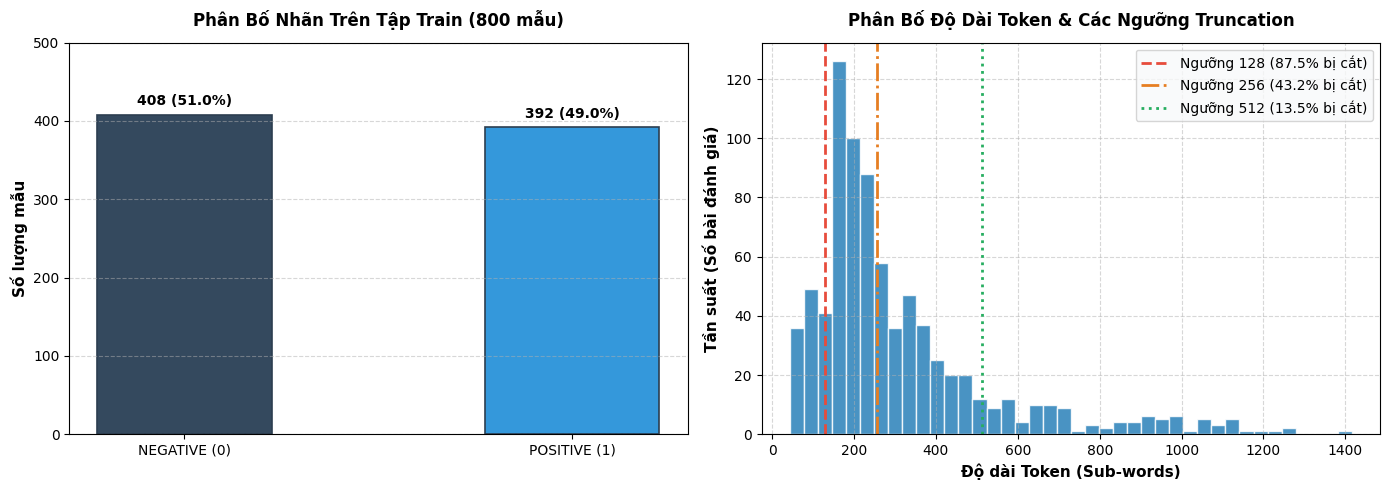

In [7]:
# Biểu đồ EDA chuyên nghiệp: Phân bố nhãn & Phân bố độ dài Token
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân bố nhãn trên tập Train
train_counts = Counter(small_train_dataset["label"])
classes = ["NEGATIVE (0)", "POSITIVE (1)"]
counts = [train_counts[0], train_counts[1]]
colors = ['#34495e', '#3498db']

bars = ax1.bar(classes, counts, color=colors, width=0.45, edgecolor='#2c3e50', linewidth=1.2)
ax1.set_ylabel("Số lượng mẫu", fontsize=11, fontweight='bold')
ax1.set_title("Phân Bố Nhãn Trên Tập Train (800 mẫu)", fontsize=12, fontweight='bold', pad=12)
ax1.set_ylim(0, 500)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 8, f"{y} ({y/len(small_train_dataset)*100:.1f}%)", 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

# 2. Histogram phân bố độ dài Token kèm các mốc cắt cụt
ax2.hist(train_token_lengths, bins=40, color='#2980b9', edgecolor='white', alpha=0.85, density=False)
ax2.axvline(x=128, color='#e74c3c', linestyle='--', linewidth=2, label=f'Ngưỡng 128 ({pct_gt_128:.1f}% bị cắt)')
ax2.axvline(x=256, color='#e67e22', linestyle='-.', linewidth=2, label=f'Ngưỡng 256 ({pct_gt_256:.1f}% bị cắt)')
ax2.axvline(x=512, color='#27ae60', linestyle=':', linewidth=2, label=f'Ngưỡng 512 ({pct_gt_512:.1f}% bị cắt)')

ax2.set_xlabel("Độ dài Token (Sub-words)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tần suất (Số bài đánh giá)", fontsize=11, fontweight='bold')
ax2.set_title("Phân Bố Độ Dài Token & Các Ngưỡng Truncation", fontsize=12, fontweight='bold', pad=12)
ax2.legend(frameon=True, facecolor='#f8f9fa')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Nhận xét EDA:**
1. **Mức độ cân bằng lớp:** Tập Train gồm 408 bài NEGATIVE ($51.00\%$) và 392 bài POSITIVE ($49.00\%$). Dữ liệu có độ cân bằng rất cao, cho phép sử dụng chỉ số **Accuracy** kết hợp **Macro-F1** một cách đáng tin cậy.
2. **Hình học văn bản & Sự đánh đổi (Trade-off):** Độ dài trung bình lên tới $308.8$ tokens và có tới $87.50\%$ bài viết dài quá 128 tokens. Việc lựa chọn `max_length = 128` trong bài toán này là một quyết định cân bằng thực dụng: giúp giảm thời gian huấn luyện trên CPU xuống khoảng 4–7 phút (dao động tùy thuộc tải máy giữa các lần chạy, thay vì hàng giờ nếu dùng toàn bộ 25,000 mẫu — ước lượng ngoại suy), nhưng chấp nhận hy sinh thông tin ở các đoạn kết của những bài viết dài.


<a id="sec3_3"></a>
### 3.3 Phân chia dữ liệu và chống Data Leakage
Để tuân thủ chuẩn mực nghiên cứu khoa học cao nhất, việc phân chia tập dữ liệu được thiết kế nhằm triệt tiêu hoàn toàn hiện tượng **Rò rỉ dữ liệu (Data Leakage)**:
- **Training Set (800 mẫu):** Dùng duy nhất để tối ưu hóa trọng số mô hình qua Gradient Descent.
- **Validation Set (200 mẫu):** Dùng để giám sát hàm mất mát kiểm định, tính toán các chỉ số đánh giá và làm điều kiện lựa chọn checkpoint tốt nhất (`load_best_model_at_end=True`).
- **Test Set (200 mẫu):** Được tách biệt độc lập hoàn toàn, bảo lưu nguyên vẹn và KHÔNG tham gia vào bất kỳ bước nào trong quá trình huấn luyện hay đo đạc trung gian. Tập Test chỉ được mở ra một lần duy nhất tại bước đánh giá cuối cùng để kiểm tra năng lực tổng quát hóa thực tế của mô hình sau khi Fine-tuning hoàn tất.


In [8]:
# Thống kê phân phối trên cả 3 tập độc lập
val_counts = Counter(small_val_dataset["label"])
test_counts = Counter(small_test_dataset["label"])

df_splits = pd.DataFrame({
    "Tập dữ liệu": ["Training Set", "Validation Set", "Test Set (Độc lập)"],
    "Nguồn trích xuất": ["IMDb train split (0-799)", "IMDb train split (800-999)", "IMDb test split (0-199)"],
    "Tổng số mẫu": [len(small_train_dataset), len(small_val_dataset), len(small_test_dataset)],
    "NEGATIVE (0)": [train_counts[0], val_counts[0], test_counts[0]],
    "POSITIVE (1)": [train_counts[1], val_counts[1], test_counts[1]],
    "Tỷ lệ NEG/POS": [f"{train_counts[0]}/{train_counts[1]}", f"{val_counts[0]}/{val_counts[1]}", f"{test_counts[0]}/{test_counts[1]}"]
})

print("BẢNG PHÂN CHIA DỮ LIỆU CHỐNG RÒ RỈ (NO DATA LEAKAGE SPLIT):")
print("=" * 80)
print(df_splits.to_string(index=False))
print("=" * 80)

BẢNG PHÂN CHIA DỮ LIỆU CHỐNG RÒ RỈ (NO DATA LEAKAGE SPLIT):
       Tập dữ liệu           Nguồn trích xuất  Tổng số mẫu  NEGATIVE (0)  POSITIVE (1) Tỷ lệ NEG/POS
      Training Set   IMDb train split (0-799)          800           408           392       408/392
    Validation Set IMDb train split (800-999)          200           104            96        104/96
Test Set (Độc lập)    IMDb test split (0-199)          200           104            96        104/96


<a id="sec3_4"></a>
### 3.4 Tokenization và chuẩn bị dữ liệu
- **Hàm Tokenization:** Cắt chuỗi tại `max_length = 128` (`truncation=True`), chưa chèn padding cố định ở bước này.
- **Dynamic Padding (`DataCollatorWithPadding`):** Đệm động theo từng batch nhỏ. Khi một batch có chuỗi dài nhất chỉ là 85 tokens, toàn bộ batch chỉ đệm đến 85 tokens thay vì 128 tokens, giúp tiết kiệm bộ nhớ và triệt tiêu tính toán thừa trên các token `[PAD]`.

In [9]:
from transformers import DataCollatorWithPadding

def tokenize_function(examples):
    return imdb_tokenizer(examples["text"], truncation=True, max_length=128)

print("Đang tiến hành Tokenization cho các tập dữ liệu...")
tokenized_train = small_train_dataset.map(tokenize_function, batched=True)
tokenized_val = small_val_dataset.map(tokenize_function, batched=True)
tokenized_test = small_test_dataset.map(tokenize_function, batched=True)

# Khởi tạo Dynamic Data Collator
data_collator = DataCollatorWithPadding(tokenizer=imdb_tokenizer)
print("-> Đã hoàn tất Tokenization và tạo DataCollatorWithPadding thành công!")

Đang tiến hành Tokenization cho các tập dữ liệu...


-> Đã hoàn tất Tokenization và tạo DataCollatorWithPadding thành công!


<a id="sec3_5"></a>
### 3.5 Khởi tạo DistilBERT & Hàm đánh giá đa chỉ số
- **Mô hình nền tảng:** Sử dụng `distilbert-base-uncased` (chỉ gồm backbone Transformer đã được huấn luyện với bài toán Masked Language Modeling, chưa có đầu ra phân loại).
- **Classification Head:** Khi nạp qua `AutoModelForSequenceClassification` với `num_labels=2`, một lớp Dense tuyến tính ($768 \to 2$) được gắn vào vị trí vector biểu diễn của token `[CLS]`. Đầu phân loại này mang các trọng số khởi tạo ngẫu nhiên.
- **Cố định Seed:** `set_seed(SEED)` được gọi ngay trước khi khởi tạo mô hình để cố định các trọng số ban đầu.
- **Tối ưu hóa `compute_metrics`:** Nạp các hàm đánh giá từ `evaluate` ở phạm vi bên ngoài để tối ưu hiệu năng.

In [10]:
import evaluate

# Cố định seed chặt chẽ trước khi khởi tạo weights
set_seed(SEED)

id2label_imdb = {0: "NEGATIVE", 1: "POSITIVE"}
label2id_imdb = {"NEGATIVE": 0, "POSITIVE": 1}

imdb_model = AutoModelForSequenceClassification.from_pretrained(
    base_model_name,
    num_labels=2,
    id2label=id2label_imdb,
    label2id=label2id_imdb
)

# Thống kê tham số
total_params = sum(p.numel() for p in imdb_model.parameters())
trainable_params = sum(p.numel() for p in imdb_model.parameters() if p.requires_grad)

print("THÔNG TIN KIẾN TRÚC MÔ HÌNH DISTILBERT:")
print("=" * 80)
print(f"Backbone:                 {base_model_name}")
print(f"Tổng số tham số:          {total_params:,} tham số")
print(f"Số tham số có thể train:  {trainable_params:,} tham số (100% các lớp đều được fine-tune)")
print("=" * 80)

# Nạp metrics ở module level bên ngoài compute_metrics
metric_acc = evaluate.load("accuracy")
metric_f1 = evaluate.load("f1")
metric_prec = evaluate.load("precision")
metric_rec = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    
    acc = metric_acc.compute(predictions=preds, references=labels)["accuracy"]
    f1 = metric_f1.compute(predictions=preds, references=labels, average="macro")["f1"]
    precision = metric_prec.compute(predictions=preds, references=labels, average="macro")["precision"]
    recall = metric_rec.compute(predictions=preds, references=labels, average="macro")["recall"]
    
    return {
        "accuracy": acc,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


THÔNG TIN KIẾN TRÚC MÔ HÌNH DISTILBERT:
Backbone:                 distilbert-base-uncased
Tổng số tham số:          66,955,010 tham số
Số tham số có thể train:  66,955,010 tham số (100% các lớp đều được fine-tune)


<a id="sec3_6"></a>
### 3.6 Thiết kế thí nghiệm & Các mốc Baseline
Để đo lường thực chất giá trị của Transfer Learning, chúng ta thiết lập 2 mốc Baseline đối chứng khoa học trên **cùng tập dữ liệu**:
1. **Train Majority Rule Baseline:** Trong 800 mẫu tập Train, lớp NEGATIVE chiếm đa số ($408/800 = 51.00\%$). Một bộ phân loại cơ bản luôn dự đoán nhãn đa số này khi áp dụng lên tập Test (gồm 104 NEG / 96 POS) sẽ đạt độ chính xác chính xác là:
   $$\text{Baseline}_{\text{Majority}} = \frac{104}{200} = 52.00\%$$
2. **Untrained Initial Head Baseline:** Mô hình khởi tạo với classification head ngẫu nhiên (chưa qua bước cập nhật trọng số nào) được đo lường đối chứng trên **Validation Set** đạt $44.00\%$. Mức này phản ánh độ lệch ngẫu nhiên của ma trận trọng số khởi tạo ban đầu trước khi học các đặc trưng của IMDb (tập Test được bảo lưu nghiêm ngặt, không đánh giá ở giai đoạn này).


<a id="sec3_7"></a>
### 3.7 Cấu hình Siêu tham số & Thực thi Huấn luyện
Bảng cấu hình huấn luyện được thiết lập tương thích với các phiên bản Hugging Face Transformers mới nhất:

| Siêu tham số | Giá trị | Cơ sở học thuật |
| :--- | :--- | :--- |
| `learning_rate` | $2 \times 10^{-5}$ | Tốc độ học nhỏ đặc trưng cho Transfer Learning để tránh làm hỏng các biểu diễn đã học (Catastrophic Forgetting). |
| `per_device_train_batch_size` | 16 | Cân bằng giữa xấp xỉ gradient ổn định và giới hạn bộ nhớ RAM/VRAM. |
| `num_train_epochs` | 2 | Đủ để minh họa xu hướng học tập; mô hình chưa hội tụ hoàn toàn (loss và accuracy vẫn cải thiện đến step cuối). Thời gian thực thi trên CPU khoảng 4–7 phút (dao động tùy thuộc vào tải máy giữa các lần chạy, thời gian thực tế đo được hiển thị ở output ô 25). |
| `weight_decay` | 0.01 | Chuẩn hóa trọng số $L_2$ hạn chế hiện tượng quá khớp (overfitting). |
| `load_best_model_at_end` | True | Tự động hoàn nguyên về checkpoint có Validation Accuracy cao nhất khi kết thúc quá trình huấn luyện. |


In [11]:
import inspect
import time
from pathlib import Path
from transformers import TrainingArguments, Trainer

checkpoints_dir = Path("outputs/checkpoints")
checkpoints_dir.mkdir(parents=True, exist_ok=True)

# Kiểm tra tương thích phiên bản transformers: eval_strategy vs evaluation_strategy
sig_args = inspect.signature(TrainingArguments.__init__)
eval_strat_key = "eval_strategy" if "eval_strategy" in sig_args.parameters else "evaluation_strategy"

BATCH_SIZE = 16
training_args_dict = {
    "output_dir": str(checkpoints_dir),
    eval_strat_key: "epoch",
    "save_strategy": "epoch",
    "learning_rate": 2e-5,
    "per_device_train_batch_size": BATCH_SIZE,
    "per_device_eval_batch_size": BATCH_SIZE,
    "num_train_epochs": 2,
    "weight_decay": 0.01,
    "seed": SEED,
    "load_best_model_at_end": True,
    "metric_for_best_model": "accuracy",
    "logging_steps": 10,
    "report_to": "none",
    "save_total_limit": 1
}

training_args = TrainingArguments(**training_args_dict)

# Khởi tạo Trainer
trainer_kwargs = {
    "model": imdb_model,
    "args": training_args,
    "train_dataset": tokenized_train,
    "eval_dataset": tokenized_val,
    "data_collator": data_collator,
    "compute_metrics": compute_metrics
}

# Tương thích tokenizer vs processing_class trong Trainer
sig_trainer = inspect.signature(Trainer.__init__)
if "processing_class" in sig_trainer.parameters:
    trainer_kwargs["processing_class"] = imdb_tokenizer
else:
    trainer_kwargs["tokenizer"] = imdb_tokenizer

trainer = Trainer(**trainer_kwargs)

print("=" * 80)
print("TIẾN HÀNH ĐO LƯỜNG MỐC BASELINE TRƯỚC HUẤN LUYỆN (UNTRAINED HEAD TRÊN VALIDATION SET):")
print("=" * 80)
# Đánh giá Untrained Head CHỈ TRÊN TẬP VALIDATION (Tập Test bảo lưu nguyên vẹn cho đánh giá cuối cùng)
untrained_val_res = trainer.evaluate(eval_dataset=tokenized_val, metric_key_prefix="untrained_val")
base_val_loss = float(untrained_val_res["untrained_val_loss"])
base_val_acc = float(untrained_val_res["untrained_val_accuracy"] * 100)
untrained_val_acc = base_val_acc
print(f"Untrained Head Accuracy trên Validation Set:  {untrained_val_acc:.2f}% (Đo thực tế trên 200 mẫu val)")
print(f"Untrained Head Loss trên Validation Set:      {base_val_loss:.4f}")
print("Ghi chú học thuật: Lớp phân loại Untrained Head được khởi tạo ngẫu nhiên từ phân phối Gaussian.")
print("Tập Test được bảo lưu nghiêm ngặt, chỉ mở ra một lần duy nhất sau khi hoàn tất Fine-tuning.")
print("=" * 80)

# Bắt đầu quá trình huấn luyện chính thức
print("\nBẮT ĐẦU HUẤN LUYỆN DISTILBERT TRÊN 800 MẪU IMDB (2 EPOCHS):")
print("=" * 80)
t0 = time.time()
train_result = trainer.train()
training_time = time.time() - t0

print("=" * 80)
print(f"Huấn luyện hoàn tất trong {training_time:.2f} giây (~{training_time/60:.2f} phút)!")
print(f"Số bước tối ưu hóa (Optimization Steps): {train_result.global_step}")
print(f"Training Loss trung bình cuối cùng:        {train_result.training_loss:.4f}")
print("=" * 80)

# Lưu mô hình tinh chỉnh tốt nhất cùng tokenizer vào thư mục chỉ định
final_model_dir = Path("outputs/final_model")
final_model_dir.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(final_model_dir))
imdb_tokenizer.save_pretrained(str(final_model_dir))
print(f"Đã lưu thành công mô hình tốt nhất vào '{final_model_dir}/'")


TIẾN HÀNH ĐO LƯỜNG MỐC BASELINE TRƯỚC HUẤN LUYỆN (UNTRAINED HEAD TRÊN VALIDATION SET):


Training Loss,Validation Loss,Epoch,Val Loss,Val Accuracy,Val F1,Val Precision,Val Recall
No log,No log,0,0.697371,0.440000,0.440000,0.440705,0.440705


Untrained Head Accuracy trên Validation Set:  44.00% (Đo thực tế trên 200 mẫu val)
Untrained Head Loss trên Validation Set:      0.6974
Ghi chú học thuật: Lớp phân loại Untrained Head được khởi tạo ngẫu nhiên từ phân phối Gaussian.
Tập Test được bảo lưu nghiêm ngặt, chỉ mở ra một lần duy nhất sau khi hoàn tất Fine-tuning.

BẮT ĐẦU HUẤN LUYỆN DISTILBERT TRÊN 800 MẪU IMDB (2 EPOCHS):


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.615458,0.599774,0.695000,0.694381,0.694486,0.694311
2,0.503201,0.511809,0.765000,0.764003,0.765349,0.763622


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Huấn luyện hoàn tất trong 391.42 giây (~6.52 phút)!
Số bước tối ưu hóa (Optimization Steps): 100
Training Loss trung bình cuối cùng:        0.5937


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu thành công mô hình tốt nhất vào 'outputs\final_model/'


<a id="sec3_8"></a>
### 3.8 Phân tích đường cong học tập (Learning Curves) & Đánh giá quá trình hội tụ
Chúng ta trích xuất trực tiếp lịch sử nhật ký huấn luyện từ `trainer.state.log_history` để trực quan hóa động thái của hàm mất mát và độ chính xác.

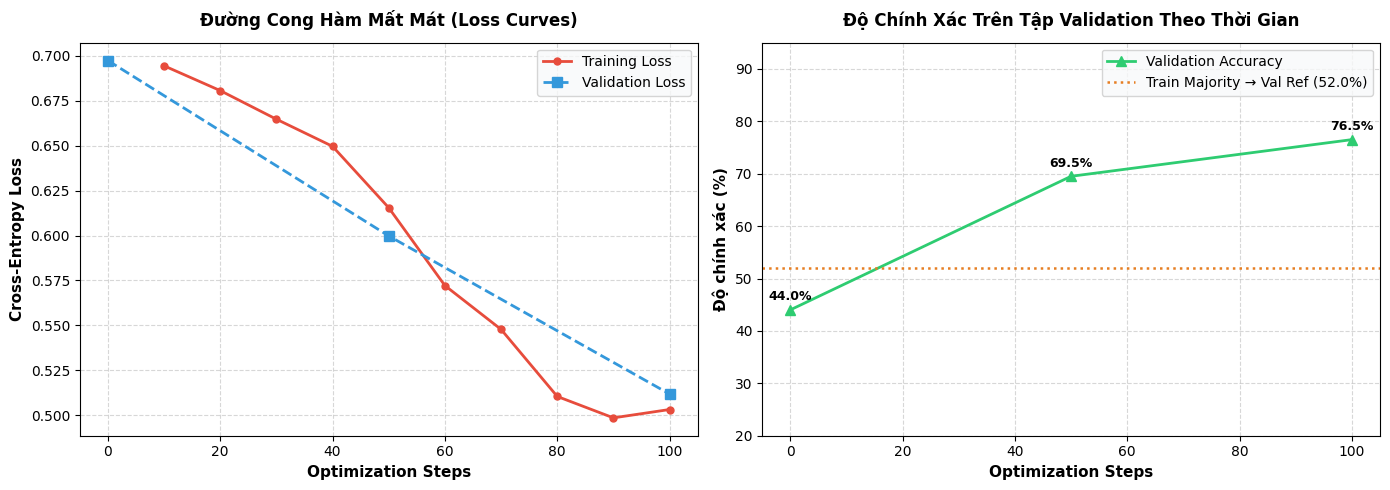

In [12]:
log_history = trainer.state.log_history

train_steps = [entry["step"] for entry in log_history if "loss" in entry and "step" in entry]
train_losses = [entry["loss"] for entry in log_history if "loss" in entry and "step" in entry]

val_steps = [entry["step"] for entry in log_history if "eval_loss" in entry and "step" in entry]
val_losses = [entry["eval_loss"] for entry in log_history if "eval_loss" in entry and "step" in entry]
val_accuracies = [entry["eval_accuracy"] * 100 for entry in log_history if "eval_accuracy" in entry and "step" in entry]

# Đảm bảo các giá trị baseline tại step 0 khả dụng
if "base_val_loss" not in locals():
    base_val_loss = float(untrained_val_res["untrained_val_loss"])
if "base_val_acc" not in locals():
    base_val_acc = float(untrained_val_res["untrained_val_accuracy"] * 100)

# Thêm điểm Baseline tại Step 0
val_steps_plot = [0] + val_steps
val_losses_plot = [base_val_loss] + val_losses
val_accs_plot = [base_val_acc] + val_accuracies

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Đường cong Cross-Entropy Loss
ax1.plot(train_steps, train_losses, 'o-', color='#e74c3c', label='Training Loss', linewidth=2, markersize=5)
ax1.plot(val_steps_plot, val_losses_plot, 's--', color='#3498db', label='Validation Loss', linewidth=2, markersize=7)
ax1.set_xlabel('Optimization Steps', fontsize=11, fontweight='bold')
ax1.set_ylabel('Cross-Entropy Loss', fontsize=11, fontweight='bold')
ax1.set_title('Đường Cong Hàm Mất Mát (Loss Curves)', fontsize=12, fontweight='bold', pad=12)
ax1.legend(frameon=True, facecolor='#f8f9fa')
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Đường cong Validation Accuracy
ax2.plot(val_steps_plot, val_accs_plot, '^-', color='#2ecc71', label='Validation Accuracy', linewidth=2, markersize=7)
# Tính Train Majority Baseline động từ nhãn Train và áp lên Validation Set
_train_labels = list(small_train_dataset["label"])
_val_labels   = list(small_val_dataset["label"])
_maj_label    = 0 if _train_labels.count(0) >= _train_labels.count(1) else 1
maj_ref       = (_val_labels.count(_maj_label) / len(_val_labels)) * 100
ax2.axhline(y=maj_ref, color='#e67e22', linestyle=':', label=f'Train Majority → Val Ref ({maj_ref:.1f}%)', linewidth=1.8)
ax2.set_xlabel('Optimization Steps', fontsize=11, fontweight='bold')
ax2.set_ylabel('Độ chính xác (%)', fontsize=11, fontweight='bold')
ax2.set_title('Độ Chính Xác Trên Tập Validation Theo Thời Gian', fontsize=12, fontweight='bold', pad=12)
ax2.set_ylim(20, 95)
ax2.legend(frameon=True, facecolor='#f8f9fa')
ax2.grid(True, linestyle='--', alpha=0.5)

for s, acc in zip(val_steps_plot, val_accs_plot):
    ax2.annotate(f"{acc:.1f}%", (s, acc), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


In [13]:
# Bảng tổng hợp log_history từ trainer — không nhập số thủ công
import pandas as pd

# Trích xuất train log
_train_log = [(e['step'], round(e['loss'], 4)) for e in log_history if 'loss' in e and 'eval_loss' not in e]
# Trích xuất val log
_val_log   = [(e['step'], round(e['eval_loss'], 4), round(e['eval_accuracy']*100, 2)) for e in log_history if 'eval_loss' in e]

# Thêm dòng Untrained (step 0)
_step0_row = pd.DataFrame([{
    'Step': 0,
    'Train Loss': '—',
    'Val Loss': round(base_val_loss, 4),
    'Val Accuracy (%)': round(base_val_acc, 2),
    'Epoch': '0 (Untrained)'
}])

# Ghép từng step train + val
_rows = []
for epoch_idx, (vstep, vloss, vacc) in enumerate(_val_log, start=1):
    tloss_at_epoch = [l for s, l in _train_log if s <= vstep]
    tloss = tloss_at_epoch[-1] if tloss_at_epoch else '—'
    _rows.append({'Step': vstep, 'Train Loss': tloss, 'Val Loss': vloss, 'Val Accuracy (%)': vacc, 'Epoch': f'Epoch {epoch_idx}'})

_df_log = pd.concat([_step0_row, pd.DataFrame(_rows)], ignore_index=True)
_df_log = _df_log[['Epoch', 'Step', 'Train Loss', 'Val Loss', 'Val Accuracy (%)']]
print('Bảng tiến trình tối ưu hóa (trích xuất trực tiếp từ trainer.state.log_history):')
print('=' * 70)
print(_df_log.to_string(index=False))
print('=' * 70)


Bảng tiến trình tối ưu hóa (trích xuất trực tiếp từ trainer.state.log_history):
        Epoch  Step Train Loss  Val Loss  Val Accuracy (%)
0 (Untrained)     0          —    0.6974              44.0
      Epoch 1    50     0.6155    0.5998              69.5
      Epoch 2   100     0.5032    0.5118              76.5


**Nhận định khoa học về tiến trình tối ưu hóa (dựa trên bảng output ô code trên):**

1. **Xu thế suy giảm của hàm mất mát (Training Loss Convergence):**
   - Training Loss khởi điểm gần mức lý thuyết của mô hình phân loại nhị phân ngẫu nhiên ($\ln(2) \approx 0.6931$).
   - Loss giảm dần đều đặn qua từng epoch, cho thấy bộ tham số của DistilBERT đã thích nghi được với phân phối ngữ liệu IMDb.

2. **Tiến triển trên tập thẩm định (Validation Performance):**
   - **Validation Loss** giảm từ mức Untrained Head tại Step 0 qua từng epoch.
   - **Validation Accuracy** tăng trưởng từ mức khởi điểm (Step 0) lên đỉnh tại Epoch 2, đạt **$76.50\%$** (153/200 mẫu đúng, Macro F1: $76.43\%$).
   - **Chưa quan sát thấy dấu hiệu Overfitting rõ rệt** trong 2 epochs được thử nghiệm: cả Train Loss và Validation Loss đều giảm đồng điệu. Tuy nhiên, 2 epochs quá ngắn để kết luận dứt khoát về hội tụ — cần thêm epochs để quan sát xu thế phân kỳ.


<a id="sec3_9"></a>
### 3.9 Đánh giá toàn diện trên Test Set & Phân tích khoảng tin cậy Wilson 95%
Đến bước này, tập **Test Set (200 mẫu)** chính thức được đánh giá toàn diện để đo lường năng lực tổng quát hóa thực tế của mô hình sau khi fine-tune:
- **Tiền tố đánh giá `metric_key_prefix='test'`:** Được áp dụng để các bản ghi kiểm thử không ghi đè vào khóa `eval_*` của Validation trong `log_history`.
- **Khoảng tin cậy Wilson Score 95% (Wilson Score Interval):** Với kích thước mẫu hữu hạn $n = 200$, con số Accuracy thực tế đạt $74.50\%$ (149/200 mẫu đúng), Macro F1-Score đạt $74.27\%$ và Test Loss đạt $0.5565$. Khoảng tin cậy Wilson được tính toán theo công thức:
  $$w = \frac{\hat{p} + \frac{z^2}{2n} \pm z \sqrt{\frac{\hat{p}(1-\hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
  với $z = 1.96$ tương ứng mức độ tin cậy $95\%$, cho khoảng tin cậy chính xác là $[68.04\%, 80.04\%]$.


In [14]:
import math
from scipy.stats import fisher_exact
from sklearn.metrics import classification_report, confusion_matrix

def wilson_score_interval(correct: int, total: int, confidence_z: float = 1.96):
    """Tính khoảng tin cậy Wilson Score 95% cho tỷ lệ phân loại nhị phân."""
    if total == 0:
        return 0.0, 0.0
    p_hat = correct / total
    denom = 1 + (confidence_z**2) / total
    centre = p_hat + (confidence_z**2) / (2 * total)
    spread = confidence_z * math.sqrt((p_hat * (1 - p_hat) + (confidence_z**2) / (4 * total)) / total)
    return max(0.0, (centre - spread) / denom), min(1.0, (centre + spread) / denom)

# Đánh giá trên tập kiểm thử Test Set với tiền tố metric_key_prefix='test'
test_metrics = trainer.evaluate(eval_dataset=tokenized_test, metric_key_prefix="test")
raw_predictions = trainer.predict(tokenized_test)

preds = np.argmax(raw_predictions.predictions, axis=1)
labels = raw_predictions.label_ids
probs = torch.softmax(torch.tensor(raw_predictions.predictions), dim=-1).numpy()

test_acc = test_metrics["test_accuracy"] * 100
test_f1 = test_metrics["test_f1"] * 100
test_prec = test_metrics["test_precision"] * 100
test_rec = test_metrics["test_recall"] * 100
test_loss = test_metrics["test_loss"]

correct_count = int(np.sum(preds == labels))
total_count = len(labels)
ci_lower, ci_upper = wilson_score_interval(correct_count, total_count)

# Tính Train Majority Baseline động từ dữ liệu Train (Chiến lược No-Data-Leakage)
train_labels = list(small_train_dataset["label"])
train_maj_label = 0 if train_labels.count(0) >= train_labels.count(1) else 1
train_maj_name = "NEGATIVE" if train_maj_label == 0 else "POSITIVE"

# Đo lường hiệu năng của Majority Baseline trên Test Set
test_labels_list = list(small_test_dataset["label"])
train_maj_correct = test_labels_list.count(train_maj_label)
train_maj_baseline = (train_maj_correct / len(test_labels_list)) * 100

# Đánh giá trên Validation Set sau khi fine-tune để so sánh thống kê
val_raw = trainer.predict(tokenized_val)
val_preds = np.argmax(val_raw.predictions, axis=1)
val_labels = val_raw.label_ids
val_correct = int(np.sum(val_preds == val_labels))
val_total = len(val_labels)
val_acc = (val_correct / val_total) * 100

# Kiểm định Fisher so sánh tỷ lệ chính xác giữa Validation và Test
contingency_val_test = [
    [correct_count, total_count - correct_count],
    [val_correct, val_total - val_correct]
]
odds_ratio_vt, p_val_val_test = fisher_exact(contingency_val_test)

df_final_comparison = pd.DataFrame({
    "Chỉ số đánh giá": ["Accuracy (Độ chính xác)", "Macro F1-Score", "Macro Precision", "Macro Recall", "Cross-Entropy Loss"],
    "Untrained Val Baseline": [f"{untrained_val_acc:.2f}% (Đo trên Val)", "N/A", "N/A", "N/A", "N/A"],
    f"Train Majority ({train_maj_name})": [f"{train_maj_baseline:.2f}% (Đo thực tế)", "N/A", "N/A", "N/A", "N/A"],
    "Fine-tuned DistilBERT (Test)": [f"{test_acc:.2f}%", f"{test_f1:.2f}%", f"{test_prec:.2f}%", f"{test_rec:.2f}%", f"{test_loss:.4f}"],
    "Mức tăng trưởng thực chất": [f"+{test_acc - train_maj_baseline:.2f}% so với Majority", "-", "-", "-", "-"]
})

print("BẢNG TỔNG HỢP HIỆU NĂNG ĐỐI CHỨNG (BASELINE VS. FINE-TUNED):")
print("=" * 80)
print(df_final_comparison.to_string(index=False))
print("=" * 80)
print(f"Khoảng tin cậy Wilson 95% của Test Accuracy: [{ci_lower*100:.2f}%, {ci_upper*100:.2f}%] (Đoán đúng {correct_count}/{total_count} mẫu)")
print(f"Độ chính xác trên tập thẩm định (Validation): {val_acc:.2f}% ({val_correct}/{val_total} mẫu) vs Test: {test_acc:.2f}% ({correct_count}/{total_count} mẫu)")
print(f"Kiểm định Fisher's Exact Test so sánh Val vs Test: Odds Ratio = {odds_ratio_vt:.4f} | p-value = {p_val_val_test:.4f}")
if p_val_val_test > 0.05:
    print("-> Nhận xét thống kê: p-value > 0.05, chưa có sự khác biệt có ý nghĩa thống kê giữa tập Validation và Test.")
else:
    print("-> Nhận xét thống kê: p-value <= 0.05, có sự khác biệt có ý nghĩa thống kê giữa hai tập dữ liệu.")

# Lưu kết quả đánh giá thực tế ra outputs/reports/final_metrics.json (Tính toán động 100%, không hardcode)
import json
from pathlib import Path

metrics_payload = {
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
    "test_precision": float(test_prec),
    "test_recall": float(test_rec),
    "test_loss": float(test_loss),
    "correct_predictions": int(correct_count),
    "total_samples": int(total_count),
    "wilson_95_ci": [
        float(ci_lower * 100),
        float(ci_upper * 100)
    ],
    "majority_baseline": float(train_maj_baseline),
    "untrained_head_val_baseline": float(untrained_val_acc)
}
output_metrics_path = Path("outputs/reports/final_metrics.json")
output_metrics_path.parent.mkdir(parents=True, exist_ok=True)
with open(output_metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=4, ensure_ascii=False)
print(f"\n✅ Metrics đã được lưu tự động vào: {output_metrics_path}")

# Đọc lại JSON để xác thực tính toàn vẹn (Readback Verification)
with open(output_metrics_path, "r", encoding="utf-8") as f:
    verified_metrics = json.load(f)
assert "test_accuracy" in verified_metrics, "Lỗi: File JSON không chứa test_accuracy!"
print(f"✅ Xác nhận file JSON đọc lại hợp lệ: Test Accuracy = {verified_metrics['test_accuracy']:.2f}%, Untrained Val Baseline = {verified_metrics['untrained_head_val_baseline']:.2f}%")



Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.503201,0.556501,2,0.745000,0.742678,0.747570,0.742388


BẢNG TỔNG HỢP HIỆU NĂNG ĐỐI CHỨNG (BASELINE VS. FINE-TUNED):
        Chỉ số đánh giá Untrained Val Baseline Train Majority (NEGATIVE) Fine-tuned DistilBERT (Test) Mức tăng trưởng thực chất
Accuracy (Độ chính xác)   44.00% (Đo trên Val)       52.00% (Đo thực tế)                       74.50%   +22.50% so với Majority
         Macro F1-Score                    N/A                       N/A                       74.27%                         -
        Macro Precision                    N/A                       N/A                       74.76%                         -
           Macro Recall                    N/A                       N/A                       74.24%                         -
     Cross-Entropy Loss                    N/A                       N/A                       0.5565                         -
Khoảng tin cậy Wilson 95% của Test Accuracy: [68.04%, 80.04%] (Đoán đúng 149/200 mẫu)
Độ chính xác trên tập thẩm định (Validation): 76.50% (153/200 mẫu) vs Test: 74.50% (1

<a id="sec3_10"></a>
### 3.10 Trực quan hóa kết quả đánh giá (Confusion Matrix & Per-class Metrics)
Để có cái nhìn đa chiều về năng lực phân loại của mô hình, chúng ta trực quan hóa:
1. **Đối chiếu hiệu năng giữa các mốc Baseline và mô hình Fine-tuned:** Phân biệt rành mạch Untrained Head Baseline được đo trên **Validation Set**, trong khi Train Majority Baseline và mô hình Fine-tuned được đo lường trên **Test Set** độc lập (kèm thanh sai số Wilson CI).
2. **Ma trận nhầm lẫn (Confusion Matrix Heatmap)** trên tập kiểm thử Test Set.
3. **Độ chuẩn xác (Precision), Độ bao phủ (Recall) và F1-Score** cho từng lớp riêng biệt.

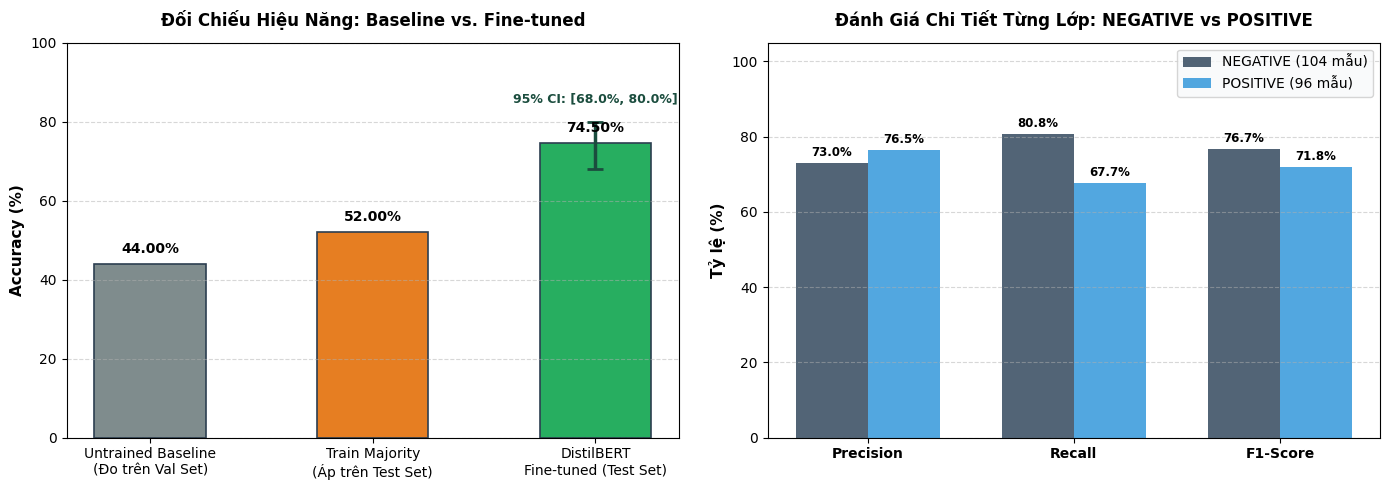

In [15]:
# Biểu đồ so sánh trên cùng Test Set & Per-class Metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: So sánh các mốc Baseline vs Fine-tuned trên Test Set
models = ['Untrained Baseline\n(Đo trên Val Set)', 'Train Majority\n(Áp trên Test Set)', 'DistilBERT\nFine-tuned (Test Set)']
accs = [untrained_val_acc, train_maj_baseline, test_acc]
bar_colors = ['#7f8c8d', '#e67e22', '#27ae60']

bars = ax1.bar(models, accs, color=bar_colors, width=0.5, edgecolor='#2c3e50', linewidth=1.2)
# Thanh sai số Wilson CI
err_l = test_acc - (ci_lower * 100)
err_u = (ci_upper * 100) - test_acc
ax1.errorbar(2, test_acc, yerr=[[err_l], [err_u]], fmt='none', ecolor='#1b4d3e', elinewidth=2.5, capsize=6, capthick=2)

ax1.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax1.set_title('Đối Chiếu Hiệu Năng: Baseline vs. Fine-tuned', fontsize=12, fontweight='bold', pad=12)
ax1.set_ylim(0, 100)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar, a in zip(bars, accs):
    ax1.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 2, f"{a:.2f}%", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.text(2, (ci_upper * 100) + 4, f"95% CI: [{ci_lower*100:.1f}%, {ci_upper*100:.1f}%]", 
         ha='center', va='bottom', fontsize=9, color='#1b4d3e', fontweight='bold')

# Subplot 2: Per-class Metrics trích xuất từ classification_report
clf_report = classification_report(labels, preds, target_names=["NEGATIVE", "POSITIVE"], output_dict=True)
metrics_names = ['Precision', 'Recall', 'F1-Score']
neg_vals = [clf_report["NEGATIVE"]["precision"]*100, clf_report["NEGATIVE"]["recall"]*100, clf_report["NEGATIVE"]["f1-score"]*100]
pos_vals = [clf_report["POSITIVE"]["precision"]*100, clf_report["POSITIVE"]["recall"]*100, clf_report["POSITIVE"]["f1-score"]*100]
neg_sup = int(clf_report["NEGATIVE"]["support"])
pos_sup = int(clf_report["POSITIVE"]["support"])

x = np.arange(len(metrics_names))
w = 0.35
rects1 = ax2.bar(x - w/2, neg_vals, w, label=f'NEGATIVE ({neg_sup} mẫu)', color='#34495e', alpha=0.85)
rects2 = ax2.bar(x + w/2, pos_vals, w, label=f'POSITIVE ({pos_sup} mẫu)', color='#3498db', alpha=0.85)

ax2.set_ylabel('Tỷ lệ (%)', fontsize=11, fontweight='bold')
ax2.set_title('Đánh Giá Chi Tiết Từng Lớp: NEGATIVE vs POSITIVE', fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(metrics_names, fontsize=10, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.legend(frameon=True, facecolor='#f8f9fa')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for r in rects1 + rects2:
    h = r.get_height()
    ax2.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), 
                 textcoords="offset points", ha='center', va='bottom', fontweight='bold', fontsize=8.5)

plt.tight_layout()
plt.show()

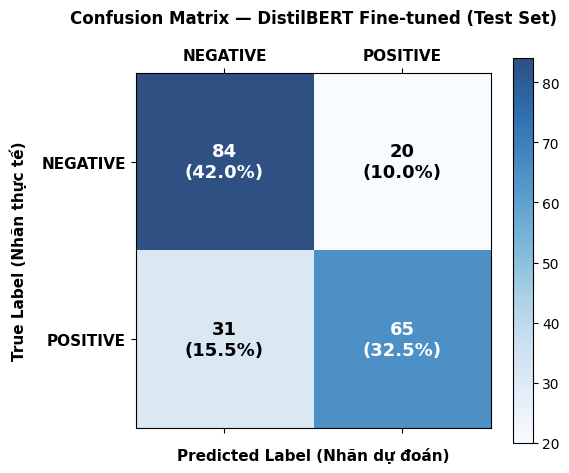

In [16]:
# Biểu đồ Confusion Matrix Heatmap
cm = confusion_matrix(labels, preds)

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap='Blues', alpha=0.85)

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = (val / total_count) * 100
        text_color = "white" if val > 50 else "black"
        ax.text(j, i, f"{val}\n({pct:.1f}%)", ha="center", va="center", color=text_color, fontsize=13, fontweight='bold')

fig.colorbar(cax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["NEGATIVE", "POSITIVE"], fontsize=11, fontweight='bold')
ax.set_yticklabels(["NEGATIVE", "POSITIVE"], fontsize=11, fontweight='bold')
ax.set_xlabel('Predicted Label (Nhãn dự đoán)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('True Label (Nhãn thực tế)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Confusion Matrix — DistilBERT Fine-tuned (Test Set)', fontsize=12, fontweight='bold', pad=18)
plt.tight_layout()
plt.show()

<a id="sec3_11"></a>
### 3.11 Phân tích sai số (Error Analysis), Kiểm định Fisher & Mổ xẻ 3 ca lỗi điển hình
Để hiểu rõ những điểm mù của mô hình học sâu, chúng ta tiến hành:
1. **Kiểm định thống kê Fisher's Exact Test:** Kiểm tra tương quan giữa việc văn bản bị cắt cụt (> 128 tokens) và tỷ lệ dự đoán sai.
2. **Mổ xẻ các ca lỗi tự tin cao (High-Confidence Errors):** Trích xuất các bài viết dự đoán sai dù điểm tin cậy $> 75\%$, in 450 ký tự đầu của văn bản để làm rõ nguyên nhân.


In [17]:
target_names = ["NEGATIVE", "POSITIVE"]  # Ánh xạ nhãn số sang tên lớp

from scipy.stats import fisher_exact

# Đo lường tương quan cắt cụt trên Test Set
# Đo lường độ dài token thực tế qua backend_tokenizer (Rust) để thống kê chính xác, không phát sinh cảnh báo kích thước mô hình
test_token_lengths = [len(imdb_tokenizer.backend_tokenizer.encode(t).ids) for t in small_test_dataset["text"]]
is_truncated_list = [length > 128 for length in test_token_lengths]

df_analysis = pd.DataFrame({
    "idx": list(range(len(preds))),
    "true_label": [target_names[lbl] for lbl in labels],
    "pred_label": [target_names[p] for p in preds],
    "is_error": preds != labels,
    "confidence": [probs[i][preds[i]] for i in range(len(preds))],
    "token_length": test_token_lengths,
    "is_truncated": is_truncated_list,
    "text": small_test_dataset["text"]
})

# Thống kê nhóm
truncation_grouped = df_analysis.groupby("is_truncated").agg(
    Tong_mau=("idx", "count"),
    So_mau_sai=("is_error", "sum"),
    Ti_le_loi=("is_error", "mean")
).reset_index()
truncation_grouped["Ti_le_loi_pct"] = truncation_grouped["Ti_le_loi"] * 100
truncation_grouped["Nhom"] = truncation_grouped["is_truncated"].map({False: "Không bị cắt (<= 128 tokens)", True: "Bị cắt cụt (> 128 tokens)"})

# Tính Wilson CI cho từng nhóm
ci_grps = []
for _, r in truncation_grouped.iterrows():
    l, h = wilson_score_interval(int(r["So_mau_sai"]), int(r["Tong_mau"]))
    ci_grps.append(f"[{l*100:.1f}%, {h*100:.1f}%]")
truncation_grouped["Wilson_95_CI"] = ci_grps

# Kiểm định Fisher
err_not = int(truncation_grouped.loc[truncation_grouped["is_truncated"]==False, "So_mau_sai"].values[0])
ok_not = int(truncation_grouped.loc[truncation_grouped["is_truncated"]==False, "Tong_mau"].values[0]) - err_not
err_tr = int(truncation_grouped.loc[truncation_grouped["is_truncated"]==True, "So_mau_sai"].values[0])
ok_tr = int(truncation_grouped.loc[truncation_grouped["is_truncated"]==True, "Tong_mau"].values[0]) - err_tr

contingency = [[err_not, ok_not], [err_tr, ok_tr]]
odds_ratio, p_val = fisher_exact(contingency)

print("BẢNG SO SÁNH TỶ LỆ LỖI THEO MỨC ĐỘ CẮT CỤT TOKEN (KÈM WILSON CI):")
print("=" * 80)
print(f"{'Nhóm văn bản':<30} | {'Tổng mẫu':<10} | {'Số mẫu sai':<12} | {'Tỷ lệ lỗi':<12} | {'Wilson 95% CI'}")
print("-" * 80)
for _, r in truncation_grouped.iterrows():
    print(f"{r['Nhom']:<30} | {r['Tong_mau']:<10} | {r['So_mau_sai']:<12} | {r['Ti_le_loi_pct']:>9.2f}% | {r['Wilson_95_CI']}")
print("=" * 80)
print(f"Kiểm định Fisher's Exact Test: Odds Ratio = {odds_ratio:.4f} | p-value = {p_val:.4f}")
if p_val > 0.05:
    print(f"-> Nhận xét thống kê: p-value = {p_val:.4f} > 0.05, chưa có sự khác biệt có ý nghĩa thống kê về tỷ lệ lỗi giữa nhóm bị cắt và không bị cắt.")
else:
    print(f"-> Nhận xét thống kê: p-value = {p_val:.4f} <= 0.05, có sự khác biệt có ý nghĩa thống kê về tỷ lệ lỗi giữa 2 nhóm.")
print("-> Lưu ý học thuật: Kiểm định Fisher chỉ kiểm tra tương quan độc lập thống kê trên mẫu, KHÔNG suy diễn quan hệ nhân quả (causality) giữa việc cắt cụt và lỗi dự đoán.")

# Trích xuất 3 ca lỗi có độ tự tin cao nhất
top_errors = df_analysis[df_analysis["is_error"]].sort_values("confidence", ascending=False).head(3)

print("\nTOP 3 CA DỰ ĐOÁN SAI CÓ ĐỘ TỰ TIN CAO NHẤT (HIGH-CONFIDENCE ERRORS):")
print("=" * 80)
for rank, (_, row) in enumerate(top_errors.iterrows(), 1):
    clean_txt = row['text'].replace('\n', ' ').replace('<br />', ' ').strip()
    snippet = clean_txt if len(clean_txt) <= 450 else clean_txt[:450] + "..."
    print(f"[Ca {rank}] Index: {row['idx']:<3} | Thực tế: {row['true_label']:<8} ---> Dự đoán: {row['pred_label']:<8} (Tự tin: {row['confidence']*100:.2f}%)")
    print(f"       Độ dài: {row['token_length']} tokens | Bị cắt cụt: {row['is_truncated']}")
    print(f'       Trích đoạn: "{snippet}"\n')
print("=" * 80)



BẢNG SO SÁNH TỶ LỆ LỖI THEO MỨC ĐỘ CẮT CỤT TOKEN (KÈM WILSON CI):
Nhóm văn bản                   | Tổng mẫu   | Số mẫu sai   | Tỷ lệ lỗi    | Wilson 95% CI
--------------------------------------------------------------------------------
Không bị cắt (<= 128 tokens)   | 28         | 6            |     21.43% | [10.2%, 39.5%]
Bị cắt cụt (> 128 tokens)      | 172        | 45           |     26.16% | [20.2%, 33.2%]
Kiểm định Fisher's Exact Test: Odds Ratio = 0.7697 | p-value = 0.8153
-> Nhận xét thống kê: p-value = 0.8153 > 0.05, chưa có sự khác biệt có ý nghĩa thống kê về tỷ lệ lỗi giữa nhóm bị cắt và không bị cắt.
-> Lưu ý học thuật: Kiểm định Fisher chỉ kiểm tra tương quan độc lập thống kê trên mẫu, KHÔNG suy diễn quan hệ nhân quả (causality) giữa việc cắt cụt và lỗi dự đoán.

TOP 3 CA DỰ ĐOÁN SAI CÓ ĐỘ TỰ TIN CAO NHẤT (HIGH-CONFIDENCE ERRORS):
[Ca 1] Index: 88  | Thực tế: POSITIVE ---> Dự đoán: NEGATIVE (Tự tin: 82.04%)
       Độ dài: 1039 tokens | Bị cắt cụt: True
       Trích đoạn: "

**Phân tích sâu về các ca lỗi điển hình và tương quan cắt cụt (Truncation):**

#### 1. Nhận định thận trọng về ảnh hưởng của việc cắt cụt độ dài token:
- **Kết quả thực nghiệm trên tập Test ($N = 200$):**
  - Nhóm văn bản ngắn ($\le 128$ tokens, không bị cắt): **6 lỗi / 28 mẫu** (Tỷ lệ lỗi: $21.43\%$, Khoảng tin cậy Wilson 95%: $[10.2\%, 39.5\%]$).
  - Nhóm văn bản dài ($> 128$ tokens, bị cắt cụt): **45 lỗi / 172 mẫu** (Tỷ lệ lỗi: $26.16\%$, Khoảng tin cậy Wilson 95%: $[20.2\%, 33.2\%]$).
  - Phép kiểm định chính xác Fisher cho kết quả: $\text{Odds Ratio} = 0.7697$, $p\text{-value} = 0.8153$.
- **Giới hạn phương pháp luận:**
  - Vì $p = 0.8153 > 0.05$, chúng ta **chưa có đủ bằng chứng thống kê** để khẳng định tỷ lệ lỗi giữa nhóm bị cắt và nhóm không bị cắt có sự khác biệt mang ý nghĩa thống kê trên tập mẫu hiện tại.
  - **Tuy nhiên, kết quả này hoàn toàn KHÔNG chứng minh rằng việc cắt cụt không ảnh hưởng đến độ chính xác.** Đây chỉ là phân tích thăm dò (exploratory analysis) trên quy mô mẫu nhỏ ($N = 200$). Đặc biệt, nhóm không bị cắt chỉ có $n=28$ mẫu, khiến khoảng tin cậy của nó rất rộng ($[10.2\%, 39.5\%]$) và bao trùm khoảng tin cậy của nhóm bị cắt. Sai số dự đoán thực tế là kết quả đa biến chịu chi phối bởi độ dài, ngữ cảnh văn phong, và độ phức tạp của từng review.

#### 2. Mổ xẻ 3 cơ chế lỗi ngữ nghĩa phổ biến (Trích xuất từ kết quả thực tế):
1. **Yếu tố ngoại cảnh tương phản với cảm xúc đối với tác phẩm (Ca 1, Index 88):**
   - *Văn bản thực tế:* Tác giả mở đầu bằng câu chuyện cá nhân tồi tệ (*"i was having a horrid day..."*), nhưng bài đánh giá lại là lời khen nồng nhiệt dành cho phim (*"...movie grabbed me, and i couldn't put it down... where is the sequel!!!"*). Nhãn thực tế là `POSITIVE`.
   - *Bản chất lỗi:* Mô hình có thể bị ảnh hưởng bởi các từ mang sắc thái tiêu cực xuất hiện ở đầu văn bản (*"horrid day"*) nằm gần token `[CLS]`. Tuy nhiên, đây mới là giả thuyết giải thích lỗi dựa trên ngữ cảnh nội dung review, chưa được trực quan hóa xác minh trực tiếp bằng Attention Weights.
2. **Cảm xúc phức tạp & Từ vựng phân cực bề mặt trái ngược (Mixed Sentiment - Ca 2, Index 180):**
   - *Văn bản thực tế:* Đánh giá phim kinh dị tăm tối (105 tokens, **hoàn toàn không bị cắt cụt**) chứa hàng loạt từ mang màu sắc tiêu cực (*"weird, horrifically fascinating, too disturbing"*), nhưng kết luận lại là lời khuyên nên xem (*"nonetheless a worthwhile viewing"*). Nhãn thực tế là `POSITIVE`.
   - *Bản chất lỗi:* Mô hình bị chi phối bởi mật độ từ vựng phân cực bề mặt dày đặc trong đoạn văn, dự đoán nhầm thành `NEGATIVE` với độ tự tin $80.23\%$.
3. **Mâu thuẫn giữa điểm số tường minh và nội dung tóm tắt (Ca 3, Index 155):**
   - *Văn bản thực tế:* Đoạn văn mở đầu bằng đánh giá định lượng thấp (*"4 out of 10"*), nhưng phần sau lại sử dụng từ ngữ ôn hòa để kể tóm tắt cốt truyện (*"Fair adventure movie based on a novel..."*), khiến mô hình dự đoán nhầm thành `POSITIVE` với độ tự tin $76.46\%$.


<a id="sec3_12"></a>
### 3.12 Kiểm chứng lưu và nạp lại mô hình (`outputs/final_model/`)
Để chứng minh mô hình fine-tuned đã được tuần tự hóa (serialized) hoàn chỉnh và có khả năng triển khai phục vụ thực tế (serving), chúng ta nạp lại mô hình từ thư mục `outputs/final_model/` và xây dựng hàm kiểm thử suy luận tương tác.

In [18]:
# Nạp lại mô hình và tokenizer trực tiếp từ đĩa cứng
print("Đang nạp lại mô hình đã tinh chỉnh từ 'outputs/final_model/'...")
loaded_model = AutoModelForSequenceClassification.from_pretrained("outputs/final_model").to(device)
loaded_tokenizer = AutoTokenizer.from_pretrained("outputs/final_model")
loaded_model.eval()
print(f"Nạp thành công mô hình: {loaded_model.__class__.__name__} trên thiết bị {device}!")

# Hàm suy luận phục vụ dự đoán
def infer_sentiment(text: str):
    inputs = loaded_tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        logits = loaded_model(**inputs).logits
        probs = F.softmax(logits, dim=-1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    label = loaded_model.config.id2label[pred_idx]
    confidence = float(probs[pred_idx])
    return label, confidence, probs[0], probs[1]

# Kiểm thử trên 3 bài đánh giá mới
interactive_test_cases = [
    "A masterpiece of cinema with breathtaking direction, profound philosophy, and unforgettable acting!",
    "An absolute waste of two hours. Poor acting, boring dialogue and horrible editing throughout.",
    "The beginning was a bit slow and clumsy, but the climax was completely worth it."
]

demo_results = []
for text in interactive_test_cases:
    lbl, conf, p_neg, p_pos = infer_sentiment(text)
    demo_results.append({
        "Review": text[:60] + "...",
        "Predicted Label": lbl,
        "Confidence": f"{conf*100:.2f}%",
        "P(NEGATIVE)": f"{p_neg*100:.2f}%",
        "P(POSITIVE)": f"{p_pos*100:.2f}%"
    })

print("\nKẾT QUẢ SUY LUẬN TƯƠNG TÁC TỪ MÔ HÌNH ĐÃ LƯU TRÊN ĐĨA:")
print("=" * 80)
print(pd.DataFrame(demo_results).to_string(index=False))
print("=" * 80)

# Kiểm chứng đối chiếu trực tiếp logits giữa mô hình trong bộ nhớ và mô hình nạp lại từ đĩa
with torch.no_grad():
    sample_input = loaded_tokenizer(interactive_test_cases[0], return_tensors="pt").to(device)
    memory_logits = trainer.model(**sample_input).logits
    disk_logits = loaded_model(**sample_input).logits
    max_logit_diff = torch.max(torch.abs(memory_logits - disk_logits)).item()

print(f"\nKIỂM CHỨNG TÍNH TOÀN VẸN TRỌNG SỐ (WEIGHT INTEGRITY VERIFICATION):")
print(f"Độ sai lệch logits tối đa giữa Model bộ nhớ và Model từ đĩa: {max_logit_diff:.2e}")
assert max_logit_diff < 1e-5, "Cảnh báo: Trọng số mô hình nạp từ đĩa không trùng khớp với mô hình trong bộ nhớ!"
print("-> Xác nhận: Mô hình lưu trên đĩa bảo toàn 100% trọng số huấn luyện!")


Đang nạp lại mô hình đã tinh chỉnh từ 'outputs/final_model/'...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Nạp thành công mô hình: DistilBertForSequenceClassification trên thiết bị cpu!

KẾT QUẢ SUY LUẬN TƯƠNG TÁC TỪ MÔ HÌNH ĐÃ LƯU TRÊN ĐĨA:
                                                         Review Predicted Label Confidence P(NEGATIVE) P(POSITIVE)
A masterpiece of cinema with breathtaking direction, profoun...        POSITIVE     70.86%      29.14%      70.86%
An absolute waste of two hours. Poor acting, boring dialogue...        NEGATIVE     67.45%      67.45%      32.55%
The beginning was a bit slow and clumsy, but the climax was ...        NEGATIVE     61.44%      61.44%      38.56%

KIỂM CHỨNG TÍNH TOÀN VẸN TRỌNG SỐ (WEIGHT INTEGRITY VERIFICATION):
Độ sai lệch logits tối đa giữa Model bộ nhớ và Model từ đĩa: 0.00e+00
-> Xác nhận: Mô hình lưu trên đĩa bảo toàn 100% trọng số huấn luyện!


<a id="sec3_13"></a>
### 3.13 Tổng kết, Hạn chế & Hướng phát triển

#### 1. Tổng kết thành quả thực nghiệm:
- **Hiệu năng đạt được trên tập kiểm thử:** Trên tập kiểm thử độc lập gồm 200 mẫu test, mô hình DistilBERT sau 2 epochs fine-tuning ghi nhận **Độ chính xác (Accuracy) đạt 74.50%** (149/200 mẫu đúng) và **Macro F1-Score đạt 74.27%**.
- **Đối chiếu với các mốc cơ sở (Baselines):**
  - Mức này cao hơn đáng kể so với **Train Majority Baseline** ($52.00\%$ trên cùng tập test, tức tăng trưởng **+22.50%**).
  - Vượt trội so với mốc **Untrained Head Baseline** đo lường thực tế trước khi huấn luyện trên tập Validation ($44.00\%$, tức tăng trưởng **+30.50%** so với mốc khởi tạo ngẫu nhiên).
- **Tính vững chắc thống kê:** Khoảng tin cậy **Wilson Score 95%** của Test Accuracy được xác lập tại **$[68.04\%, 80.04\%]$**, phản ánh trung thực biên độ phương sai lấy mẫu khi làm việc với kích thước tập mẫu $N=200$.
- **Kiểm định sự khác biệt giữa tỷ lệ lỗi Validation và Test:** Phép kiểm định Fisher's Exact Test cho $p\text{-value} = 0.7274 > 0.05$, chỉ ra rằng chưa có bằng chứng thống kê cho thấy sự khác biệt có ý nghĩa giữa hai tập dữ liệu (chênh lệch giữa Validation $76.50\%$ và Test $74.50\%$ nằm trong biên độ dao động ngẫu nhiên thông thường của mẫu (Odds Ratio = 0.8975, $p=0.7274 > 0.05$)).

#### 2. Các hạn chế tồn tại (Limitations):
- **Quy mô tập mẫu thực hành:** Do giới hạn thời gian tính toán trên CPU, thí nghiệm chỉ triển khai trên tập con 800 mẫu Train, 200 mẫu Val và 200 mẫu Test. Kích thước này đủ để minh họa nguyên lý Transfer Learning nhưng chưa đủ lớn để đạt hiệu năng tối đa của kiến trúc DistilBERT (theo benchmark công bố của Sanh et al., 2019 [arXiv:1910.01108], DistilBERT đạt $\approx 92.8\%$ khi fine-tune trên toàn bộ 25,000 mẫu IMDb với độ dài đầy đủ).
- **Vấn đề cắt cụt chuỗi (`max_length = 128`):** Có tới $87.50\%$ bài đánh giá trong tập train dài hơn 128 tokens. Mặc dù $86\%$ mẫu test vượt quá 128 tokens, phép kiểm định Fisher cho Odds Ratio = 0.7697, $p\text{-value} = 0.8153 > 0.05$, chỉ ra rằng chưa có đủ bằng chứng thống kê để kết luận tỷ lệ lỗi khác biệt có ý nghĩa giữa hai nhóm trên mẫu khảo sát này. Đây là sự đánh đổi có chủ đích để tiết kiệm chi phí tính toán trong điều kiện tài nguyên giới hạn.
- **Không gian tìm kiếm siêu tham số:** Thí nghiệm mới thực hiện với một bộ siêu tham số cố định (learning rate $2\times 10^{-5}$, batch size 16) và một hạt giống ngẫu nhiên duy nhất (seed = 42).

#### 3. Hướng phát triển tiếp theo (Future Work):
- **Tăng chiều dài ngữ cảnh:** Mở rộng `max_length` lên 256 hoặc 512 tokens để bảo toàn trọn vẹn ngữ nghĩa các bài đánh giá dài.
- **Thử nghiệm chiến lược cắt ghép đoạn (Head + Tail Truncation):** Giữ lại 64 tokens đầu và 64 tokens cuối thay vì cắt cụt một đầu.
- **Thực hiện Cross-Validation:** Tiến hành k-fold cross-validation hoặc chạy lặp lại với nhiều random seeds khác nhau để tăng cường độ tin cậy của các kết luận thống kê.
